# OLS regression on popularity
**Question 1**: How popular will a track be and which pre-release features move the fit score

**Question 2**: Is OLS a good fit for prediction?
- Ward hierarchical clustering to choose k, then Minibatch k-means clustering on all songs to attempt to find simialr features
- Basic interaction terms used in ft engineering
- Run `bt4211-project.ipynb` first; it saves `tracks_clean.pkl`

# 1) Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display
SEED = 42
Path("figures").mkdir(exist_ok=True); Path("outputs").mkdir(exist_ok=True)
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "axes.titleweight": "bold", "figure.dpi": 110})

tracks = pd.read_pickle("tracks_clean.pkl")
# popularity 0 is mostly a collection artefact (EDA E1, E4), so it is left out of the model
t = tracks[tracks["popularity"] > 0].reset_index(drop=True).copy()
print(f"{len(t):,} songs with popularity > 0 (of {len(tracks):,})")

76,585 songs with popularity > 0 (of 81,343)


# 2) Features
- $\log_2$ for the right-skewed features (duration capped at p99.5, speechiness, liveness)
- binary flags for explicit, collaboration, 4/4 time and non-music tracks
- every continuous feature is **standardised** ($z = \frac{x - \bar{x}}{s}$), so each coefficient is the change in popularity for a 1 SD increase and interaction terms are on a common scale
- genre enters as fractional multi-hot weights: each of a song's $n$ genre labels gets $\frac{1}{n}$, with `pop` as the reference genre

In [2]:
t["log_duration"] = np.log2(t["duration_min"].clip(upper=t["duration_min"].quantile(0.995)))
t["log_speechiness"] = np.log2(t["speechiness"] + 0.01)
t["log_liveness"] = np.log2(t["liveness"] + 0.01)
t["tempo"] = t["tempo"].fillna(t["tempo"].median())          # undefined only for non_music tracks
t["is_4_4"] = t["time_signature"].eq(4).fillna(False).astype(int)
for c in ["explicit", "collab", "non_music"]:
    t[c] = t[c].astype(int)

AUDIO = ["danceability", "energy", "loudness", "log_speechiness", "acousticness",
         "instrumentalness", "log_liveness", "valence", "tempo", "log_duration"]
Z = StandardScaler().fit_transform(t[AUDIO])
for i, c in enumerate(AUDIO):
    t["z_" + c] = Z[:, i]

# fractional multi-hot genre weights
G = pd.get_dummies(t["genres"].explode().replace({"songwriter": "singer-songwriter"})).groupby(level=0).max().astype(float)
G.columns = ["g_" + c.replace("-", "_") for c in G.columns]
t = pd.concat([t, G.div(G.sum(axis=1), axis=0)], axis=1)
GENRES = [c for c in G.columns if c != "g_pop"]
print(f"{len(AUDIO)} audio features, {len(GENRES)} genre weights (reference: pop)")

10 audio features, 112 genre weights (reference: pop)


# 3) Clustering songs by sound
Ward clustering needs the full $n \times n$ distance matrix, which is too large for 76,000 songs, so it runs on a random sample of 5,000. We cut the dendrogram at $k = 3$ to $8$ and score each cut with the silhouette coefficient. $k = 2$ is skipped because it only separates in  strumental and acoustic tracks from everything else.

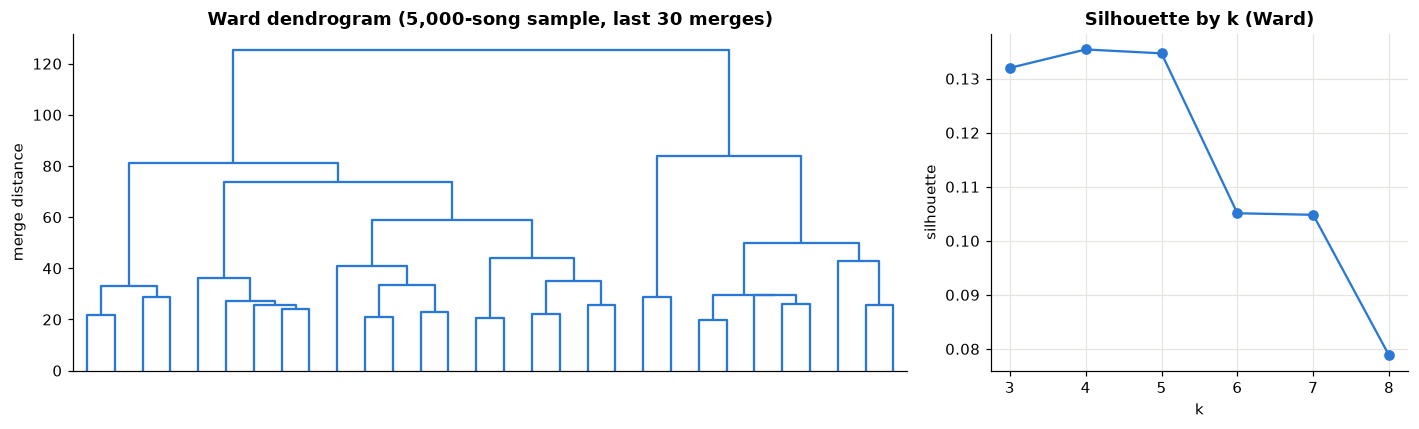

In [3]:
rng = np.random.default_rng(SEED)
sample = rng.choice(len(t), 5_000, replace=False)
Zs = Z[sample]
L = linkage(Zs, method="ward")

K_RANGE = range(3, 9)
sil_ward = {k: silhouette_score(Zs, fcluster(L, k, "maxclust")) for k in K_RANGE}

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
dendrogram(L, truncate_mode="lastp", p=30, ax=axes[0], color_threshold=0, above_threshold_color=BLUE, no_labels=True)
axes[0].set_title("Ward dendrogram (5,000-song sample, last 30 merges)"); axes[0].set_ylabel("merge distance")
axes[0].grid(False)
axes[1].plot(list(sil_ward), list(sil_ward.values()), "o-", color=BLUE)
axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette"); axes[1].set_title("Silhouette by k (Ward)")
fig.tight_layout(); plt.savefig("figures/ols_01_hierarchical.png", dpi=150, bbox_inches="tight"); plt.show()

# Minibatch clustering

For each candidate $k$, MiniBatchKMeans runs on all songs, **starting from the Ward cluster centroids**. Using the hierarchical solution as the starting point is the usual way to combine the two methods: Ward picks the shape of the solution and k-means refines it at full scale. We keep the $k$ with the highest silhouette, and the adjusted Rand index (ARI) shows how far k-means moved away from the Ward labels.

,silhouette_ward,silhouette_kmeans,ARI_ward_vs_kmeans
k,,,
3,0.132,0.147,0.558
4,0.135,0.158,0.614
5,0.135,0.160,0.590
6,0.105,0.145,0.466
7,0.105,0.137,0.479
8,0.079,0.135,0.471


chosen k = 5


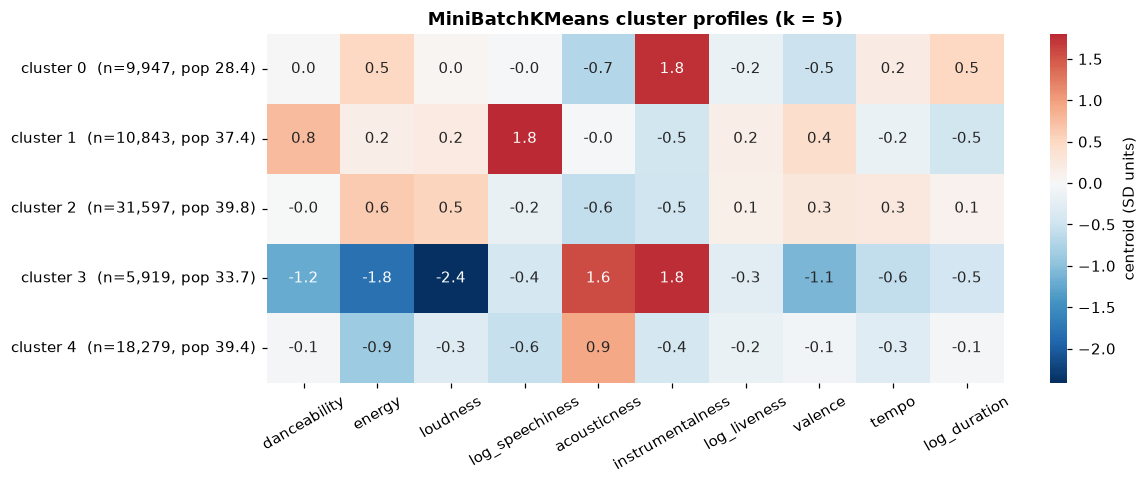

In [4]:
rows, models = [], {}
for k in K_RANGE:
    ward = fcluster(L, k, "maxclust")
    init = np.vstack([Zs[ward == j].mean(axis=0) for j in range(1, k + 1)])
    km = MiniBatchKMeans(n_clusters=k, init=init, n_init=1, batch_size=4096, random_state=SEED).fit(Z)
    models[k] = km
    rows.append({"k": k, "silhouette_ward": sil_ward[k],
                 "silhouette_kmeans": silhouette_score(Zs, km.labels_[sample]),
                 "ARI_ward_vs_kmeans": adjusted_rand_score(ward, km.labels_[sample])})
k_tbl = pd.DataFrame(rows).set_index("k")
K = int(k_tbl["silhouette_kmeans"].idxmax())
display(k_tbl.round(3))
print(f"chosen k = {K}")

t["cluster"] = models[K].labels_
centres = pd.DataFrame(models[K].cluster_centers_, columns=AUDIO)
centres["songs"] = t["cluster"].value_counts().sort_index()
centres["mean_popularity"] = t.groupby("cluster")["popularity"].mean()

fig, ax = plt.subplots(figsize=(11, 0.6 * K + 1.5))
sns.heatmap(centres[AUDIO], cmap="RdBu_r", center=0, annot=True, fmt=".1f", cbar_kws={"label": "centroid (SD units)"}, ax=ax,
            yticklabels=[f"cluster {i}  (n={n:,}, pop {p:.1f})" for i, n, p in zip(centres.index, centres.songs, centres.mean_popularity)])
ax.set_title(f"MiniBatchKMeans cluster profiles (k = {K})"); ax.tick_params(axis="x", rotation=30); ax.grid(False)
fig.tight_layout(); plt.savefig("figures/ols_02_cluster_profiles.png", dpi=150, bbox_inches="tight"); plt.show()

### Findings:

## 4. Interaction terms

Three basic interactions, each motivated by the EDA:

| Term | Question it answers |
|---|---|
| `z_danceability:z_valence` | is a danceable track worth more when it is also upbeat (the strongest non-intensity pair, $r = 0.49$)? |
| `z_energy:z_acousticness` | does energy matter differently for acoustic and electronic tracks (the intensity axis, $r = -0.73$)? |
| `explicit:z_danceability` | does explicit content pay off more on danceable tracks (explicit is concentrated in hip-hop and dance genres)? |

Squared terms are kept for the three features whose decile curves rise then fall (danceability, acousticness, duration). The full model is

In [5]:
BASE = " + ".join("z_" + c for c in AUDIO) + " + explicit + collab + is_4_4 + non_music"
SQ = " + I(z_danceability**2) + I(z_acousticness**2) + I(z_log_duration**2)"
INTER = " + z_danceability:z_valence + z_energy:z_acousticness + explicit:z_danceability"
CLUST = " + C(cluster)"
GENRE = " + " + " + ".join(GENRES)

FORMULAS = {
    "1. audio + flags": "popularity ~ " + BASE,
    "2. + squares + interactions": "popularity ~ " + BASE + SQ + INTER,
    "3. + clusters": "popularity ~ " + BASE + SQ + INTER + CLUST,
    "4. + genre (final)": "popularity ~ " + BASE + SQ + INTER + CLUST + GENRE,
}

# 5) Model fitiing
 Test and train sets of songs are split 80/20 **by artist**, so the test set scores artists the model has never seen. The models are entered in blocks (hierarchical regression), so each row of the table shows what one block adds. Standard errors are clustered by artist, because songs by the same artist are not independent.

In [6]:
t["artist"] = t["artists"].str.split(";").str[0].str.strip()
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(t, groups=t["artist"]))
train, test = t.iloc[tr_i], t.iloc[te_i]

def evaluate(y, p):
    p = np.clip(p, 0, 100)
    return {"test_RMSE": np.sqrt(np.mean((y - p) ** 2)), "test_MAE": np.mean(np.abs(y - p)),
            "test_R2": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)}

fits, rows = {}, []
for name, f in FORMULAS.items():
    res = smf.ols(f, train).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(train["artist"])[0]})
    fits[name] = res
    rows.append({"model": name, "params": len(res.params), "train_adj_R2": res.rsquared_adj,
                 **evaluate(test["popularity"], res.predict(test))})
display(pd.DataFrame(rows).set_index("model").round(4))
final = fits["4. + genre (final)"]

,params,train_adj_R2,test_RMSE,test_MAE,test_R2
model,,,,,
1. audio + flags,15,0.0751,17.1071,14.1891,0.1119
2. + squares + interactions,21,0.0965,16.8445,13.9081,0.1389
3. + clusters,25,0.1093,16.8206,13.8504,0.1414
4. + genre (final),137,0.5016,12.7475,9.4403,0.5069


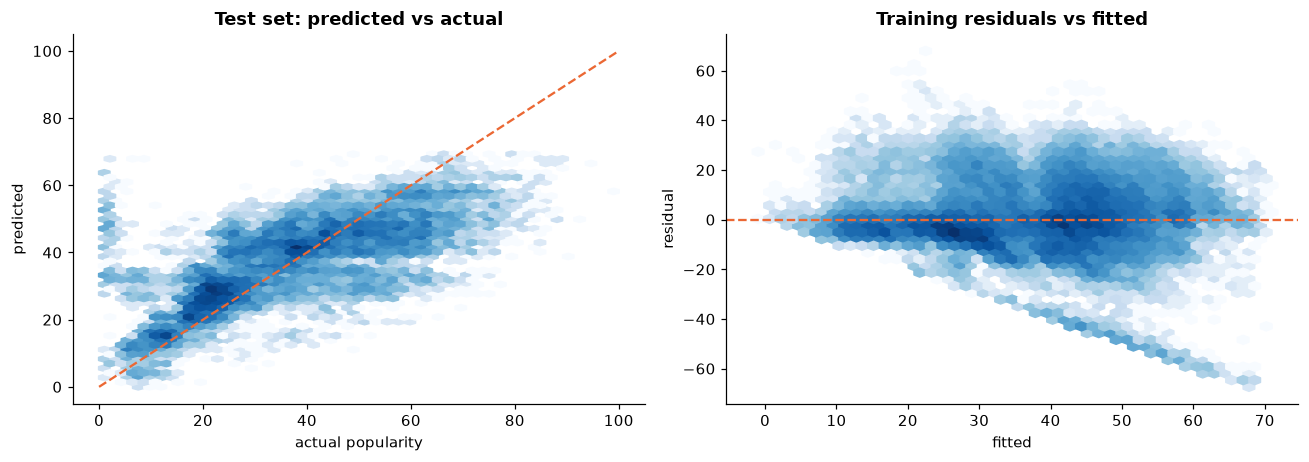

saved outputs/ols_predictions.csv and outputs/ols_coefficients.csv


In [7]:
pred = np.clip(final.predict(test), 0, 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].hexbin(test["popularity"], pred, gridsize=45, cmap="Blues", mincnt=1, bins="log")
axes[0].plot([0, 100], [0, 100], color=ORANGE, ls="--"); axes[0].grid(False)
axes[0].set_xlabel("actual popularity"); axes[0].set_ylabel("predicted"); axes[0].set_title("Test set: predicted vs actual")
axes[1].hexbin(final.fittedvalues, final.resid, gridsize=45, cmap="Blues", mincnt=1, bins="log")
axes[1].axhline(0, color=ORANGE, ls="--"); axes[1].grid(False)
axes[1].set_xlabel("fitted"); axes[1].set_ylabel("residual"); axes[1].set_title("Training residuals vs fitted")
fig.tight_layout(); plt.savefig("figures/ols_03_fit.png", dpi=150, bbox_inches="tight"); plt.show()

# outputs: a predicted score per song and a coefficient per feature
t["predicted_popularity"] = np.clip(final.predict(t), 0, 100).round(2)
t["in_test_set"] = t.index.isin(test.index)

t[["track_id", "track_name", "artists", "popularity", "predicted_popularity", "cluster", "in_test_set"]] \
    .sort_values("predicted_popularity", ascending=False).to_csv("outputs/ols_predictions.csv", index=False)
ci = final.conf_int()
coefs = pd.DataFrame({"coef": final.params, "se": final.bse, "ci_low": ci[0], "ci_high": ci[1], "p": final.pvalues})
coefs.rename_axis("term").to_csv("outputs/ols_coefficients.csv")
print("saved outputs/ols_predictions.csv and outputs/ols_coefficients.csv")

## 6) Takeaways

* **Prediction:** the final OLS explains about half the variance in popularity for artists it has never seen (test $R^2 = 0.51$).
* **What drives it:** genre is the main driver. Audio features, squared terms, interactions and sound clusters together explain only about 14%, and each audio feature moves the prediction by about 1 point per SD.
* **Creative vs marketing:** fine-tuning a track's sound has a small expected payoff compared with the half of the variance that nothing pre-release in this data explains (artist profile, playlisting, promotion). These are associations, not causal effects.
* **Limitations:**
  * popularity is a single snapshot
  * popularity-0 songs are excluded
  * the sound clusters are weakly separated (silhouette below 0.2)
* **Outputs:**
  * `outputs/ols_predictions.csv`: a predicted score for every song
  * `outputs/ols_coefficients.csv`: every coefficient with its CI